In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVR



In [13]:

df = pd.read_csv("robot_terrain_data.csv")
df.head()
#x, y = df[["grip_force_n", "object_weight_kg"]], df["success"]
#x_train, x_test, y_train, y_test= train_test_split(x, y, test_size=0.2, random_state=42)

,vibration_g,wheel_slip_pct,terrain
0,0.25,7.09,smooth
1,0.81,4.97,smooth
2,0.40,10.62,smooth
3,1.31,10.84,rough
4,0.88,15.68,rough


In [14]:
x, y = df[["vibration_g", "wheel_slip_pct"]], df["terrain"]
x_train, x_test, y_train, y_test= train_test_split(x, y, test_size=0.2, random_state=42)

In [15]:
x_test.head()

,vibration_g,wheel_slip_pct
105,1.06,13.51
108,0.85,12.38
141,0.92,21.82
55,0.34,4.02
94,0.44,11.57


In [16]:
y_test.head()

105     rough
108     rough
141     rough
55     smooth
94     smooth
Name: terrain, dtype: str

In [23]:
model= make_pipeline(StandardScaler(), SVC(kernel="linear"))
model.fit(x_train, y_train)
y_pred= model.predict(x_test)
#print("Predicted success:", y_pred[0])

Accuracy: 0.94
F1 score: 0.95


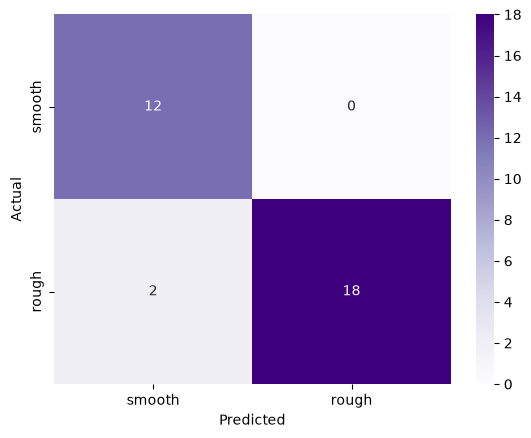

In [24]:
print("Accuracy:", round(metrics.accuracy_score(y_test, y_pred), 2))

print("F1 score:", round(
    metrics.f1_score(y_test, y_pred, pos_label="rough"), 2
))

labels = ["smooth", "rough"]

cm = metrics.confusion_matrix(y_test, y_pred, labels=labels)

sns.heatmap(
    cm,
    annot=True,
    cmap="Purples",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [3]:
df1 = pd.read_csv("robot_braking_data.csv")
X = df1[["speed_mps"]]
y = df1["stopping_distance_m"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
model = make_pipeline(StandardScaler(), SVR(kernel="rbf"))
model.fit(X_train, y_train)
y_pred = model.predict([[1.60]])

c:\Users\Lavan\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [6]:
X_test.head()

,speed_mps
19,1.98
16,1.60
15,1.35
26,2.56
4,0.37


In [7]:
y_test.head()

19    1.45
16    0.93
15    0.59
26    2.07
4     0.07
Name: stopping_distance_m, dtype: float64

In [ ]:
print("Predictions:", y_pred) 

Predictions: [0.96801095]
